# CurrencySafe


## Step 1: Imports and dataset path

In [3]:
import os, collections  # os = work with files/folders; collections = tool for counting things (used in the format check)
import numpy as np  # numpy = numerical library; "np" is its usual short name
import pandas as pd  # pandas = table library; "pd" is its usual short name
import matplotlib.pyplot as plt  # matplotlib = plotting library, used for the learning curves
from PIL import Image  # Pillow's Image = opens image files so we can read their format
from sklearn.model_selection import train_test_split  # function that splits a table into two random parts
from sklearn.utils.class_weight import compute_class_weight  # calculates a weight per class (rarer class = bigger weight)
import tensorflow as tf  # TensorFlow = the deep learning library; "tf" is its usual short name

In [2]:
dataset_path = r"C:\Users\nithi\Downloads\note detection"  # r"..." = raw string so the Windows backslashes don't break; where your dataset is
data_dir = os.path.join(dataset_path, "data", "data")  # builds the path of the folder that holds the "fake" and "real" folders

## Step 2: Check the data on disk (both checks must pass)

In [3]:
counts = {cls: sum(len(files) for _, _, files in os.walk(os.path.join(data_dir, cls))) for cls in ["fake", "real"]}  # for each class, visits all its folders and counts the image files
print(counts, "| Total:", sum(counts.values()))  # shows the counts and the grand total; expected {'fake': 2289, 'real': 4537} | Total: 6826
print("2000 folders left:", [c for c in ["fake", "real"] if os.path.exists(os.path.join(data_dir, c, "2000"))])  # lists any class that still has a 2000 folder; expected []

{'fake': 2289, 'real': 4537} | Total: 6826
2000 folders left: []


## Step 3: Table with one row per image, and image-format check

In [4]:
df = pd.DataFrame(  # builds a table from a list of rows
    [(os.path.join(data_dir, c, d, f), c, d)  # one row per image: (full file path, class, denomination)
     for c in ["fake", "real"]  # loop over the two classes
     for d in os.listdir(os.path.join(data_dir, c))  # loop over each denomination folder of that class
     for f in os.listdir(os.path.join(data_dir, c, d))],  # loop over each file in that folder
    columns=["path", "label", "denom"])  # names of the three columns
df["strat"] = df["label"] + "_" + df["denom"]  # joins label and denomination into 12 groups like "fake_500"; the split keeps each group's share equal
print(df.shape, "| repeated paths:", df["path"].duplicated().sum())  # table size and how many file paths appear twice; expected (6826, 4) | repeated paths: 0

(6826, 4) | repeated paths: 0


In [5]:
print(collections.Counter(Image.open(p).format for p in df["path"]))  # reads each file's real format and counts them; TensorFlow cannot read AVIF, so expect no AVIF in the result

Counter({'JPEG': 6815, 'PNG': 10, 'WEBP': 1})


## Step 4: Stratified 70/15/15 split and labels (fake = 0, real = 1)

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["strat"], random_state=42)  # 70% goes to train_df, 30% to temp_df; stratify keeps all 12 groups in equal proportion; random_state=42 makes the split repeatable
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strat"], random_state=42)  # splits temp_df in half: 15% validation and 15% test, again stratified
train_df, val_df, test_df = [p.assign(y=(p["label"] == "real").astype(int)) for p in (train_df, val_df, test_df)]  # adds a column y to each table: real = 1, fake = 0
print(len(train_df), len(val_df), len(test_df))  # rows in each part; expected 4778 1024 1024
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:  # loop over the three parts
    print(name, part["label"].value_counts(normalize=True).round(3).to_dict())  # share of real and fake in that part; each about real 0.665, fake 0.335

4778 1024 1024
train {'real': 0.665, 'fake': 0.335}
val {'real': 0.665, 'fake': 0.335}
test {'real': 0.665, 'fake': 0.335}


In [7]:
print(len(set(train_df["path"]) & set(val_df["path"])), len(set(train_df["path"]) & set(test_df["path"])), len(set(val_df["path"]) & set(test_df["path"])))  # counts image paths shared between two splits (train/val, train/test, val/test); expected 0 0 0, meaning no leakage

0 0 0


## Step 5: Class weights (from the training set only)

In [8]:
weights = compute_class_weight("balanced", classes=np.array(["fake", "real"]), y=train_df["label"])  # "balanced" = the rarer class gets the bigger weight; uses the training labels only
class_weight = {0: weights[0], 1: weights[1]}  # the format Keras expects: class 0 (fake) and class 1 (real) mapped to their weights
print(class_weight)  # shows the weights; expected fake about 1.49, real about 0.75

{0: np.float64(1.4903306300686214), 1: np.float64(0.7524409448818897)}


## Step 6: Image loading, augmentation and datasets

In [4]:
IMG_SIZE = (224, 224)  # every image will be resized to 224 x 224 pixels, the size MobileNetV2 expects
BATCH_SIZE = 32  # the model looks at 32 images at a time while training

In [5]:
def load_image(path, label):  # defines a function that prepares one image from its file path and label
    img = tf.io.read_file(path)  # reads the raw bytes of the image file from disk
    img = tf.image.decode_image(img, channels=3, expand_animations=False)  # turns the bytes into RGB pixels (3 colour channels, no animation frames)
    img = tf.image.resize(img, IMG_SIZE)  # resizes the image to 224 x 224
    img = tf.cast(img, tf.float32) / 255.0  # converts pixel values from 0-255 to 0-1 (normalization)
    return img, label  # hands back the finished image together with its label

In [11]:
augment = tf.keras.Sequential([  # a chain of random image changes, applied one after another
    tf.keras.layers.RandomFlip("horizontal"),  # randomly mirrors the image left to right
    tf.keras.layers.RandomRotation(0.05),  # randomly tilts the image by up to about 18 degrees
    tf.keras.layers.RandomZoom(0.1),  # randomly zooms in or out by up to 10%
    tf.keras.layers.RandomContrast(0.1),  # randomly makes the image a little lighter or darker
])  # end of the chain; used on training images only

In [12]:
def make_ds(df):  # defines a function that turns a table into a dataset for validation or test (no shuffle, no augmentation)
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["y"].values))  # pairs every file path with its 0/1 label
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)  # turns each path into a resized, normalized image (several at once)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)  # groups into batches of 32 and prepares the next batch in the background

train_ds = tf.data.Dataset.from_tensor_slices((train_df["path"].values, train_df["y"].values))  # pairs each training file path with its label
train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)  # turns each path into a resized, normalized image
train_ds = (train_ds.shuffle(256, seed=42)  # mixes the order of the images using a buffer of 256
            .batch(BATCH_SIZE)  # groups the images into batches of 32
            .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)  # applies the random augmentation to each batch of images; labels stay unchanged
            .prefetch(tf.data.AUTOTUNE))  # prepares the next batch while the model trains on the current one
val_ds, test_ds = make_ds(val_df), make_ds(test_df)  # builds the validation and test datasets with the function above

In [13]:
print(sum(1 for _ in train_ds), sum(1 for _ in val_ds), sum(1 for _ in test_ds))  # loops through every batch of each dataset (loads all images once) and counts them; expected 150 32 32

150 32 32


## Step 7: Build the model (MobileNetV2 + our own layers)

In [14]:
base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")  # loads MobileNetV2 pretrained on ImageNet, without its original 1000-category classifier
base_model.trainable = False  # freezes the pretrained layers, so stage 1 only trains our new output layer

inputs = tf.keras.Input(shape=(224, 224, 3))  # the model's entry point: images of 224 x 224 pixels with 3 colour channels
x = tf.keras.layers.Rescaling(2.0, offset=-1.0)(inputs)  # converts pixels from 0-1 to -1 to 1, which is what MobileNetV2 expects
x = base_model(x, training=False)  # passes the images through MobileNetV2; training=False keeps its normalization layers fixed
x = tf.keras.layers.GlobalAveragePooling2D()(x)  # averages each 7x7 feature map into one number, giving 1,280 numbers per image
x = tf.keras.layers.Dropout(0.3)(x)  # during training, randomly switches off 30% of the numbers so the model doesn't memorize
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)  # one output neuron; sigmoid gives the probability the note is real (0 to 1)
model = tf.keras.Model(inputs, outputs)  # joins everything from inputs to outputs into one model
model.summary()  # prints every layer and its number of weights; expected trainable params: 1,281

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Step 8: Training stage 1 (only the new output layer learns, about 25 minutes)

In [15]:

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),  # Adam = the method that adjusts the weights; 1e-3 = learning rate (size of each adjustment)
              loss="binary_crossentropy",  # the error measure for a two-class problem
              metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")])  # numbers shown during training
history = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=class_weight,  # trains for at most 10 passes, checks on validation images each epoch, and counts mistakes on fake notes more
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])  # stops if validation loss doesn't improve for 3 epochs and keeps the best weights


Epoch 1/10


C:\Users\nithi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


150/150 ━━━━━━━━━━━━━━━━━━━━ 124s 762ms/step - accuracy: 0.8801 - loss: 0.2997 - precision: 0.9345 - recall: 0.8813 - val_accuracy: 0.9385 - val_loss: 0.1558 - val_precision: 0.9304 - val_recall: 0.9809
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 113s 734ms/step - accuracy: 0.9452 - loss: 0.1552 - precision: 0.9746 - recall: 0.9420 - val_accuracy: 0.9590 - val_loss: 0.1177 - val_precision: 0.9571 - val_recall: 0.9824
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 113s 739ms/step - accuracy: 0.9552 - loss: 0.1268 - precision: 0.9808 - recall: 0.9512 - val_accuracy: 0.9609 - val_loss: 0.1142 - val_precision: 0.9520 - val_recall: 0.9912
Epoch 4/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 141s 734ms/step - accuracy: 0.9573 - loss: 0.1219 - precision: 0.9790 - recall: 0.9562 - val_accuracy: 0.9727 - val_loss: 0.0908 - val_precision: 0.9698 - val_recall: 0.9897
Epoch 5/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 137s 701ms/step - accuracy: 0.9646 - loss: 0.1018 - precision: 0.9820 - recall: 0.9644 - val_accuracy: 0.9639 - val

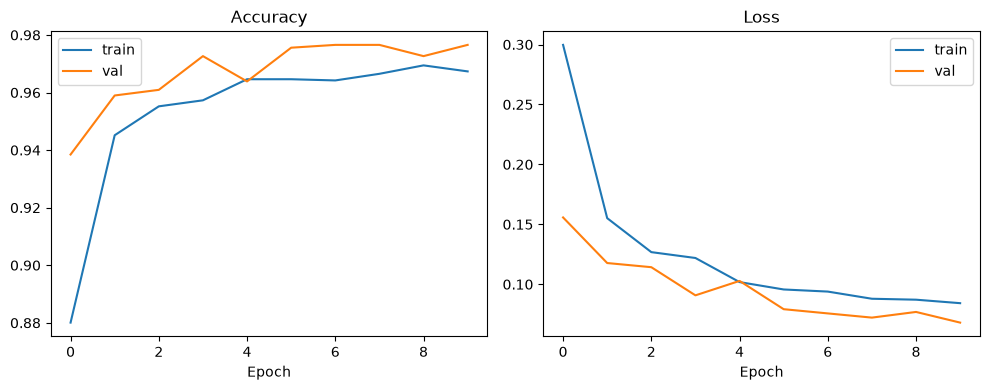

In [16]:
plt.figure(figsize=(10, 4))  # creates a blank figure 10 inches wide and 4 inches tall
plt.subplot(1, 2, 1); plt.plot(history.history["accuracy"], label="train"); plt.plot(history.history["val_accuracy"], label="val"); plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()  # left chart: training vs validation accuracy per epoch
plt.subplot(1, 2, 2); plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="val"); plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()  # right chart: training vs validation loss per epoch
plt.tight_layout(); plt.show()  # fixes the spacing so labels don't overlap, then shows the figure

## Step 9: Training stage 2 (fine-tune the last 54 layers, about 25 minutes)

In [17]:
base_model.trainable = True  # unfreezes the whole MobileNetV2 base so its layers can learn again
for layer in base_model.layers[:100]:  # loops over the first 100 layers (the early ones that detect general edges and textures)
    layer.trainable = False  # freezes them again, so only the last layers can learn
print(sum(l.trainable for l in base_model.layers), "of", len(base_model.layers), "layers trainable")  # counts the trainable layers; expected 54 of 154

54 of 154 layers trainable


In [18]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),  # same Adam method but a 100 times smaller learning rate, so the pretrained layers are only nudged
              loss="binary_crossentropy",  # same two-class error measure as before
              metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")])  # recompiling is required after changing trainable
history2 = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=class_weight,  # fine-tunes for at most 10 epochs with the same class weights; history2 keeps stage 2's numbers
                     callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])  # stops early if validation loss stops improving and keeps the best weights

Epoch 1/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9410 - loss: 0.1417 - precision: 0.9810 - recall: 0.9291 - val_accuracy: 0.9746 - val_loss: 0.0785 - val_precision: 0.9940 - val_recall: 0.9677
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.9648 - loss: 0.0928 - precision: 0.9855 - recall: 0.9613 - val_accuracy: 0.9746 - val_loss: 0.0816 - val_precision: 0.9955 - val_recall: 0.9662
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 145s 946ms/step - accuracy: 0.9732 - loss: 0.0698 - precision: 0.9891 - recall: 0.9704 - val_accuracy: 0.9814 - val_loss: 0.0646 - val_precision: 0.9955 - val_recall: 0.9765
Epoch 4/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 139s 910ms/step - accuracy: 0.9755 - loss: 0.0666 - precision: 0.9876 - recall: 0.9754 - val_accuracy: 0.9775 - val_loss: 0.0731 - val_precision: 0.9970 - val_recall: 0.9692
Epoch 5/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.9810 - loss: 0.0533 - precision: 0.9911 - recall: 0.9802 - val_accuracy: 0.9863 - v

## Step 10: Save the new model (new file name, the old file stays as a backup)

In [19]:
# model.save("currencysafe_model_v2.keras")  # saves the whole trained model (structure and weights) into one file next to this notebook

In [20]:
probs = model.predict(test_ds).ravel()  # runs all 1,024 test images through the model; returns one number per image (the probability the note is real, 0 to 1); .ravel() flattens the result into a simple list
print(probs.shape, probs[:5].round(3))  # prints how many predictions we got (expected (1024,)) and the first 5 probabilities rounded to 3 decimals

32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 516ms/step
(1024,) [1.    1.    1.    0.997 1.   ]


In [21]:
preds = (probs > 0.5).astype(int)  # turns each probability into a decision: above 0.5 = 1 (real), otherwise 0 (fake)
true = test_df["y"].values  # the true labels of the test images (fake = 0, real = 1), in the same order as the predictions
print("Test accuracy:", (preds == true).mean().round(4))  # compares each decision with the true label; the average of the matches is the share predicted correctly
print("Wrong predictions:", (preds != true).sum(), "of", len(true))  # counts how many of the 1,024 test images the model got wrong

Test accuracy: 0.9922
Wrong predictions: 8 of 1024


In [22]:
from sklearn.metrics import confusion_matrix, classification_report  # confusion_matrix = counts of each kind of right/wrong answer; classification_report = precision, recall and F1 per class
cm = confusion_matrix(true, preds, labels=[0, 1])  # builds a 2x2 table; rows = true class (0 fake, 1 real), columns = predicted class
print(cm)  # shows the table: [[fake called fake, fake called real], [real called fake, real called real]]
print("Fake notes called REAL (the costly mistake):", cm[0][1])  # row 0 (true fake), column 1 (predicted real)
print("Real notes called FAKE:", cm[1][0])  # row 1 (true real), column 0 (predicted fake)
print(classification_report(true, preds, target_names=["fake", "real"], digits=3))  # precision, recall and F1 for each class, with 3 decimals

[[339   4]
 [  4 677]]
Fake notes called REAL (the costly mistake): 4
Real notes called FAKE: 4
              precision    recall  f1-score   support

        fake      0.988     0.988     0.988       343
        real      0.994     0.994     0.994       681

    accuracy                          0.992      1024
   macro avg      0.991     0.991     0.991      1024
weighted avg      0.992     0.992     0.992      1024



In [23]:
res = test_df.assign(pred=preds)  # makes a copy of the test table with the model's decision added as a new column called pred
res["correct"] = (res["pred"] == res["y"])  # True where the model's decision matches the true label, False where it is wrong
print(res.groupby(["denom", "label"])["correct"].agg(["mean", "count"]).round(3))  # for each denomination and class: the share predicted correctly (mean) and the number of test images (count)

              mean  count
denom label              
10    fake   1.000     43
      real   0.993    143
100   fake   1.000     55
      real   1.000    101
20    fake   0.978     45
      real   1.000    136
200   fake   1.000     41
      real   1.000     82
50    fake   1.000     44
      real   1.000    127
500   fake   0.974    115
      real   0.967     92


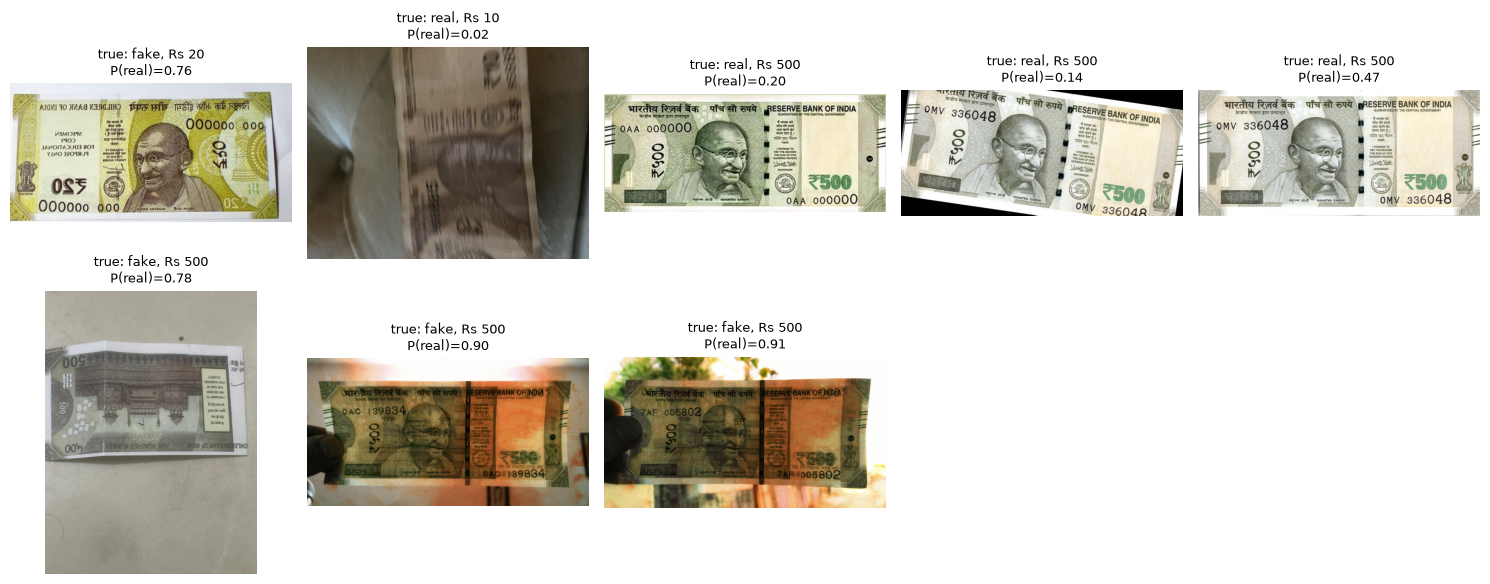

In [24]:
res["prob"] = probs  # adds the model's probability of "real" for each test image to the results table
wrong = res[~res["correct"]]  # keeps only the rows where the model was wrong (the 10 mistakes)
plt.figure(figsize=(15, 6))  # creates a blank figure 15 inches wide and 6 inches tall
for i, (_, row) in enumerate(wrong.iterrows()):  # loops over the wrong images; i = position (0 to 9), row = that image's table row
    plt.subplot(2, 5, i + 1)  # picks slot number i+1 in a grid of 2 rows and 5 columns
    plt.imshow(Image.open(row["path"]))  # opens the image file and draws it
    plt.title(f"true: {row['label']}, Rs {row['denom']}\nP(real)={row['prob']:.2f}", fontsize=9)  # title: the true class, the denomination, and how likely the model thought the note was real
    plt.axis("off")  # hides the axis numbers around the picture
plt.tight_layout(); plt.show()  # fixes the spacing so the titles don't overlap, then shows the figure

In [25]:
conf = np.maximum(probs, 1 - probs)  # confidence = how sure the model is of its own decision: 0.5 = coin flip, 1.0 = completely sure
unsure = conf < 0.70  # True for images where the model is less than 70% sure; these would be shown as "uncertain, check manually"
print("Flagged as uncertain:", unsure.sum(), "of", len(unsure))  # how many of the 1,024 test images fall in the uncertain zone
print("Mistakes inside the uncertain zone:", (unsure & (preds != true)).sum(), "of", (preds != true).sum())  # how many of the 10 mistakes would have been flagged instead of silently wrong
print("Accuracy on the confident images:", (preds[~unsure] == true[~unsure]).mean().round(4))  # accuracy when we only trust the confident predictions

Flagged as uncertain: 12 of 1024
Mistakes inside the uncertain zone: 1 of 8
Accuracy on the confident images: 0.9931


In [26]:
import re  # re = regular expressions, used to strip the "aug_<number>_" prefix from file names
def base_name(p):  # defines a helper that returns a file's name without any "aug_<number>_" prefix
    return re.sub(r"^aug_\d+_", "", os.path.basename(p))  # os.path.basename takes the file name from the path; re.sub removes the prefix, so a copy and its original get the same name
train_names = set(train_df["path"].map(base_name))  # the set of base names found in the training images
shared = test_df["path"].map(base_name).isin(train_names)  # True for each test image whose base name also appears in training (a possible copy of a training photo)
print("Test images sharing a base name with a training image:", shared.sum(), "of", len(test_df))  # how many of the 1,024 test images may have a sibling in training
print("Accuracy on test images WITHOUT a sibling:", (preds[~shared.values] == true[~shared.values]).mean().round(4))  # accuracy on the cleanest part of the test set

Test images sharing a base name with a training image: 329 of 1024
Accuracy on test images WITHOUT a sibling: 0.9928


In [27]:
def predict_note(path):  # defines a function that checks one note photo and returns a verdict and a confidence in percent
    img, _ = load_image(path, 0)  # prepares the photo exactly like the training images; the 0 is a dummy label that we ignore
    p = float(model.predict(img[None, ...], verbose=0)[0][0])  # adds a batch dimension (a batch of 1 image); the model returns the probability the note is real
    conf = max(p, 1 - p)  # how sure the model is of its own decision (0.5 = coin flip, 1.0 = completely sure)
    if conf < 0.70:  # the 70% confidence rule from the plan
        return "UNCERTAIN - check manually", f"{conf * 100:.1f}%"  # too unsure, so we don't guess; shows the confidence as a percentage with 1 decimal
    return ("REAL" if p > 0.5 else "FAKE"), f"{conf * 100:.1f}%"  # otherwise gives the verdict and the confidence as a percentage, for example 99.5%

In [28]:
print(predict_note(test_df["path"].iloc[0]), "| true label:", test_df["label"].iloc[0])  # runs the function on the first test image and prints the verdict next to the true label

('REAL', '100.0%') | true label: real


In [29]:
feature_model = tf.keras.Model(model.input, model.layers[-3].output)  # makes a smaller model that starts at the same input but stops before dropout and the final layer; layers[-3] is the pooling layer that outputs 1,280 numbers per image
print(feature_model.output.shape)  # checks the output shape; expected (None, 1280)

(None, 1280)


In [30]:
train_feats = feature_model.predict(make_ds(train_df), verbose=0)  # runs all 4,778 training images through the feature model, without augmentation; make_ds keeps the images untouched and in order; verbose=0 hides the progress bar
print(train_feats.shape)  # expected (4778, 1280): one row of 1,280 numbers per training image


(4778, 1280)


In [31]:
from sklearn.preprocessing import StandardScaler  # StandardScaler = rescales each of the 1,280 numbers to a similar range, which the SVM needs to work well
from sklearn.svm import OneClassSVM  # OneClassSVM = learns the area where normal note photos sit, from examples of normal photos only
scaler = StandardScaler().fit(train_feats)  # learns the average and spread of each number from the training images only
svm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(scaler.transform(train_feats))  # trains the SVM on the rescaled training features; nu=0.05 allows about 5% of the training images to fall outside the "normal" area

In [32]:
val_feats = feature_model.predict(make_ds(val_df), verbose=0)  # gets the 1,280 numbers for each of the 1,024 validation images (never used to train the SVM)
val_ok = svm.predict(scaler.transform(val_feats)) == 1  # the SVM answers 1 for "looks like a normal note photo" and -1 for "outlier"; this is True for accepted images
print("Validation notes accepted:", val_ok.mean().round(3))  # the share of real note photos the check lets through; expected about 0.93 to 0.97

Validation notes accepted: 0.932


In [7]:
def check_note_full(path):  # defines the final function: first checks that the photo is a note, then real/fake, then the 70% rule
    img, _ = load_image(path, 0)  # prepares the photo (resize to 224x224, pixels 0-1); the 0 is a dummy label that we ignore
    feats = feature_model.predict(img[None, ...], verbose=0)  # gets the 1,280 numbers that describe the photo; img[None, ...] makes a batch of 1 image
    if svm.predict(scaler.transform(feats))[0] == -1:  # the SVM answers -1 when the photo does not look like the note photos it was trained on
        print("This does not look like a currency note photo. Please upload a clear photo of a note.")  # rejects the image with a message
        return  # leaves the function here, so no real/fake verdict is given
    p = float(model.predict(img[None, ...], verbose=0)[0][0])  # the model's probability that the note is real
    conf = max(p, 1 - p) * 100  # how sure the model is of its own decision, as a percentage
    if conf < 70:  # the 70% confidence rule
        print(f"The model is not sure about this note (only {conf:.1f}% confident). Please check it manually.")  # too unsure, so we don't guess
    elif p > 0.5:  # the model leans towards real
        print(f"The given note is REAL, with {conf:.1f}% confidence.")  # prints the verdict and the percentage
    else:  # the model leans towards fake
        print(f"The given note is FAKE, with {conf:.1f}% confidence.")  # prints the verdict and the percentage

In [34]:
import joblib  # joblib = a library for saving Python objects (like our SVM) to a file; it comes with scikit-learn, so there is nothing to install
joblib.dump(scaler, "currencysafe_scaler.joblib")  # saves the scaler (the rescaling settings learned from the training images) into a file next to your notebook
joblib.dump(svm, "currencysafe_svm.joblib")  # saves the trained One-Class SVM into a file next to your notebook

['currencysafe_svm.joblib']

In [1]:
my_photo = r"C:\dsu\SEMESTERS\FIFTH SEM\Machine Learning\THEORY\project\WhatsApp Image 2026-11- at 12.46.51 PM.jpeg"  # CHANGE THIS to the real path of your photo; r"..." = raw string so the Windows backslashes don't break

In [2]:
check_note_full(my_photo)   # runs the check on your photo; my_photo is the path variable from the earlier cell

NameError: name 'check_note_full' is not defined

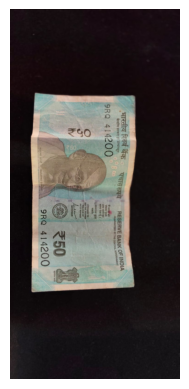

In [45]:
plt.imshow(Image.open(my_photo)); plt.axis("off"); plt.show()  # shows your photo, so you can check you picked the right file

In [6]:
import joblib  # joblib = library for loading Python objects saved to a file (we use it for the scaler and the SVM)
model = tf.keras.models.load_model("currencysafe_model_v2.keras")  # loads the trained model (structure and weights) saved at the end of Step 10, so no retraining is needed
feature_model = tf.keras.Model(model.input, model.layers[-3].output)  # rebuilds the feature extractor from the loaded model (stops at the pooling layer, 1,280 numbers per image)
scaler = joblib.load("currencysafe_scaler.joblib")  # loads the saved scaler (the rescaling settings learned from the training images)
svm = joblib.load("currencysafe_svm.joblib")  # loads the saved One-Class SVM that checks whether a photo looks like a note

In [39]:
# Cell	First words of the cell
# 3	import os, collections (all imports)
# 16	IMG_SIZE = (224, 224)
# 17	def load_image(path, label):
# 48	import joblib (the loading cell, with load_model)
# 43	def check_note_full(path):
# 45	my_photo = r"..." (put your photo’s path here)
# 46	check_note_full(my_photo)

In [40]:
# Cell	First words of the cell
# 3	import os, collections
# 4	dataset_path = r"C:\Users\nithi\Downloads\note detection"
# 8	df = pd.DataFrame(
# 11	train_df, temp_df = train_test_split(
# 16	IMG_SIZE = (224, 224)
# 17	def load_image(path, label):
# 18	augment = tf.keras.Sequential([
# 19	def make_ds(df):
# 48	import joblib (the loading cell)
# 31	probs = model.predict(test_ds).ravel()
# 32	preds = (probs > 0.5).astype(int)
# 33	from sklearn.metrics import confusion_matrix, classification_report
# 34	res = test_df.assign(pred=preds)
# 35	res["prob"] = probs
# 36	conf = np.maximum(probs, 1 - probs)

In [41]:
# 22 (base_model = ..., builds a new model)
# 24 and 28 (the two model.compile cells, which lead into training of about 50 minutes in total)
# 30 (model.save(...), which would overwrite your saved model)
# Run All, which would run all of them

In [42]:
# If the two .joblib files are missing, run 3, 4, 8, 11, 16, 17, 18, 19, then this line in a new cell: model = tf.keras.models.load_model("currencysafe_model_v2.keras"), then 39, 40, 41, 42 and 43. Then run cell 44 (import joblib with the two dump lines) to save the files again.